In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns   

df = pd.read_csv("../../ecommerce_dataset_updated.csv")
df = df.rename(columns={"Price (Rs.)": "Price",
                        "Discount (%)": "Discount",
                        "Final_Price(Rs.)": "Final_Price"})
df["Purchase_Date"] = pd.to_datetime(df["Purchase_Date"], dayfirst=True)

top_cat = df["Category"].value_counts().idxmax()
top_pay = df["Payment_Method"].value_counts().idxmax()
sns.set_theme(style="whitegrid")

## grouped bar chart

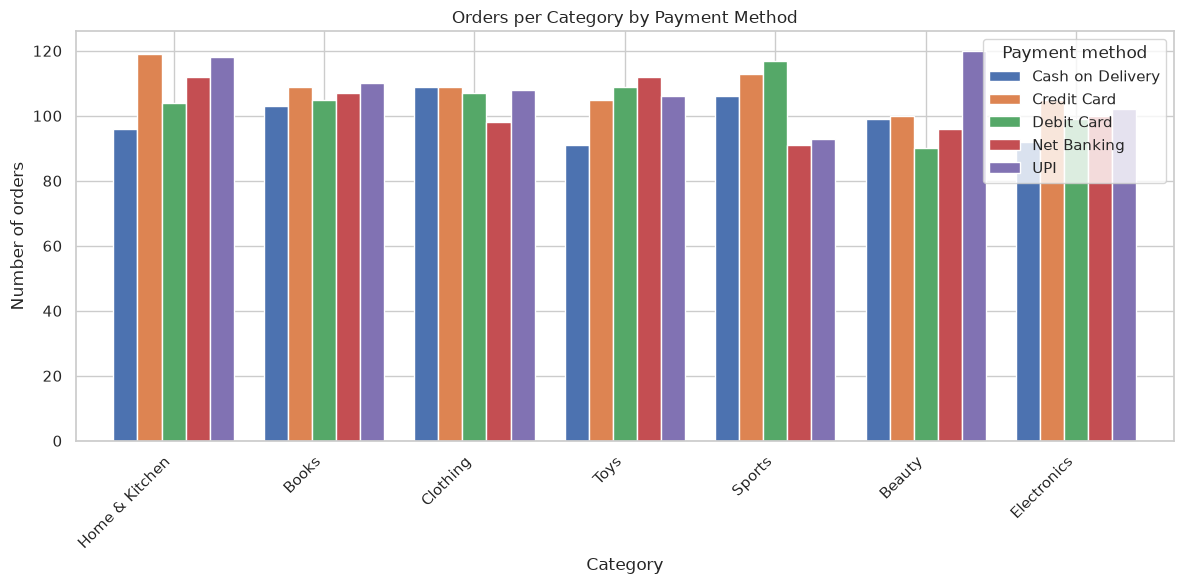

In [4]:
cross = pd.crosstab(df["Category"], df["Payment_Method"])
cross = cross.loc[cross.sum(axis=1).sort_values(ascending=False).index]  # top category first

ax = cross.plot.bar(figsize=(12, 6), width=0.8)   # stacked=False gives grouped bars
plt.title("Orders per Category by Payment Method")
plt.xlabel("Category"); plt.ylabel("Number of orders")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Payment method")
plt.tight_layout(); plt.show()

## box plot


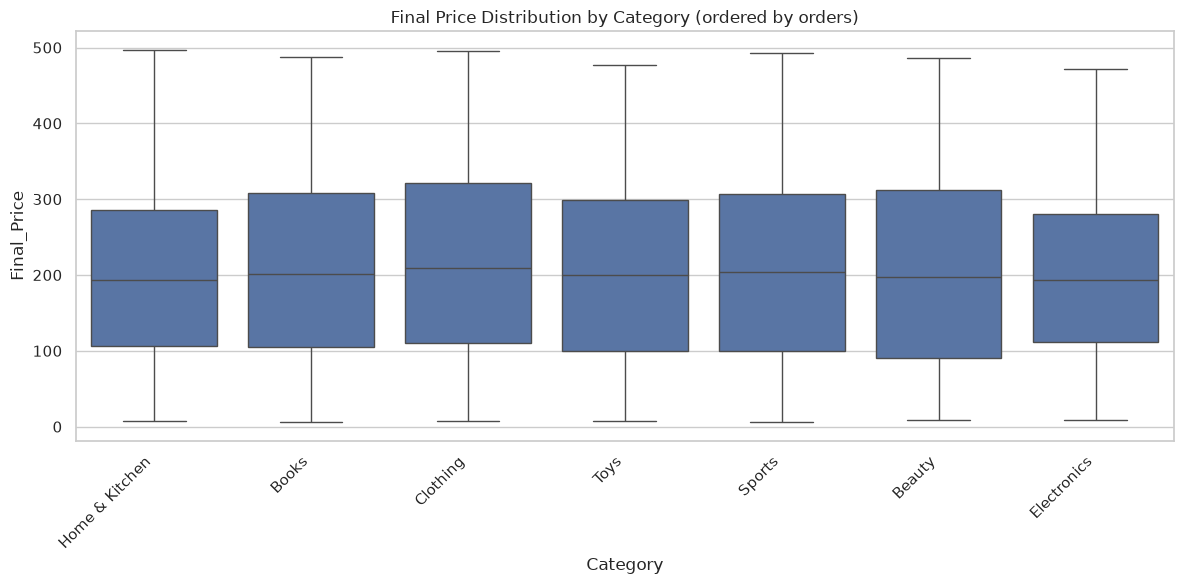

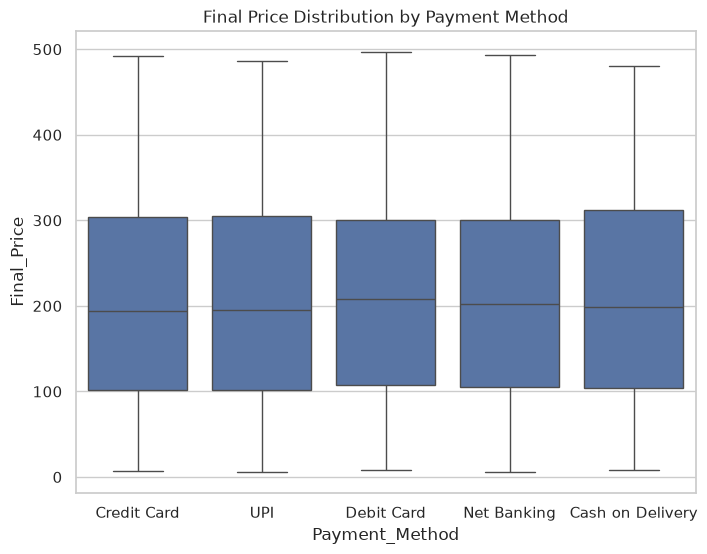

In [14]:
# Price distribution per category
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="Category", y="Final_Price", order=df["Category"].value_counts().index)
plt.title("Final Price Distribution by Category (ordered by orders)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

# Price distribution per payment method
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="Payment_Method", y="Final_Price",
            order=df["Payment_Method"].value_counts().index)
plt.title("Final Price Distribution by Payment Method"); plt.show()

# # Discount distribution per category
# plt.figure(figsize=(12, 6))
# sns.boxplot(data=df, x="Category", y="Discount")
# plt.xticks(rotation=45, ha="right"); plt.title("Discount (%) by Category")
# plt.tight_layout(); plt.show()

## violin plot

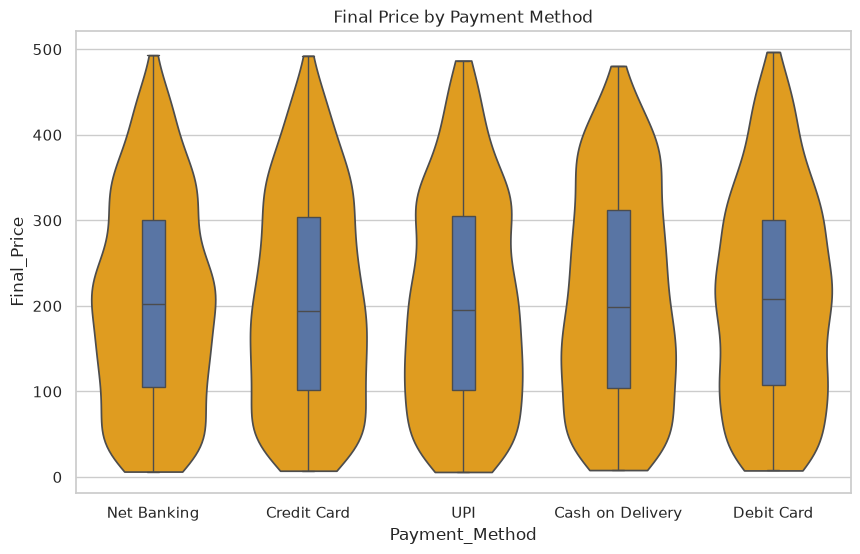

In [13]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x="Payment_Method", y="Final_Price", inner=None, color="orange", cut=0)
sns.boxplot(data=df, x="Payment_Method", y="Final_Price", width=0.15,
            boxprops={"zorder": 2}, showfliers=False)
plt.title("Final Price by Payment Method"); plt.show()

## Checking the differences 

In [12]:
from scipy import stats   # 

groups = [g["Final_Price"].values for _, g in df.groupby("Payment_Method")]
print(stats.kruskal(*groups))   # p < 0.05 means price distributions differ across payment methods

print(pd.crosstab(df["Category"], df["Payment_Method"]).pipe(lambda t: stats.chi2_contingency(t)[1]))
# p < 0.05 means payment choice depends on category

KruskalResult(statistic=np.float64(1.446264579920941), pvalue=np.float64(0.8361154674205203))
0.9398128170917388
